<a href="https://colab.research.google.com/github/subedirajib01/Scikit_learn/blob/main/Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Logistic Regression
- Many points will be classified wrongly, since the linear regressor tries to reduce mean square error (MSE). It does not cus on transforming the signal.

ODDS=P/(1-P)

The values of ODDS range from 0 to infinity. The values of probability will remain betweeen 0 to 1.



In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml


In [ ]:
titanic_data=fetch_openml("titanic", version =1,as_frame =True )
# as_frame=True this will convert the datasets into dataframe

In [ ]:
df= titanic_data['data']


In [ ]:
df['survived']=titanic_data['target']

In [ ]:
df.head()

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,survived
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0


<Axes: xlabel='survived', ylabel='count'>

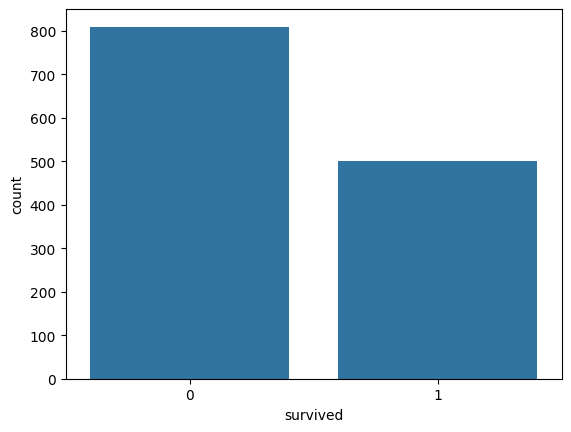

In [ ]:
sns.countplot(x='survived', data=df)

<Axes: xlabel='survived', ylabel='count'>

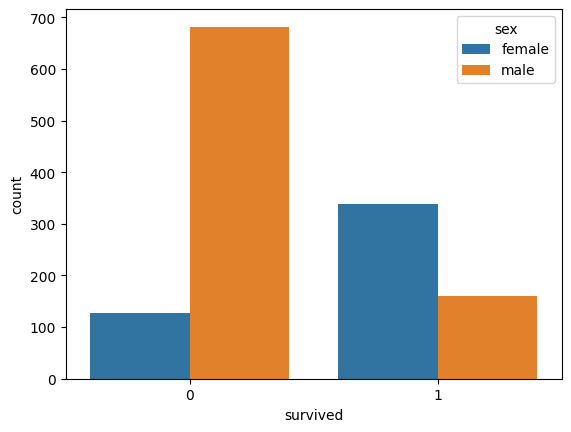

In [ ]:
sns.countplot(x='survived',hue='sex', data=df)

<Axes: xlabel='survived', ylabel='count'>

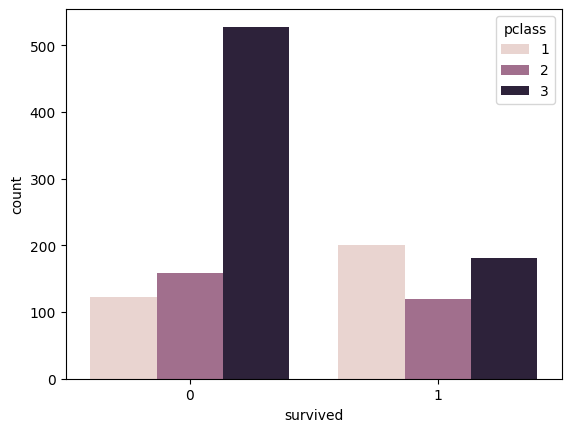

In [ ]:
sns.countplot(x='survived',hue='pclass', data=df)

<Axes: ylabel='Frequency'>

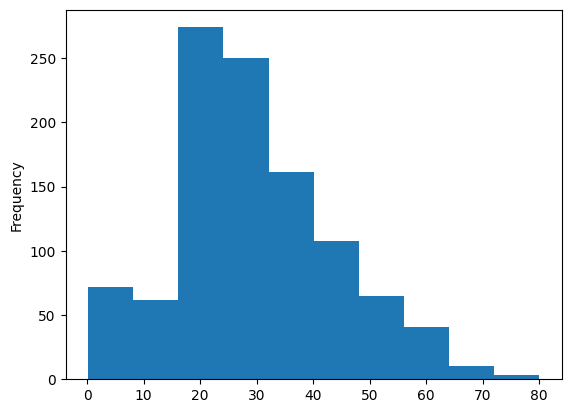

In [ ]:
df['age'].plot.hist()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   name       1309 non-null   object  
 2   sex        1309 non-null   category
 3   age        1046 non-null   float64 
 4   sibsp      1309 non-null   int64   
 5   parch      1309 non-null   int64   
 6   ticket     1309 non-null   object  
 7   fare       1308 non-null   float64 
 8   cabin      295 non-null    object  
 9   embarked   1307 non-null   category
 10  boat       486 non-null    object  
 11  body       121 non-null    float64 
 12  home.dest  745 non-null    object  
 13  survived   1309 non-null   category
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB


In [ ]:
df.isnull().sum()

,0
pclass,0
name,0
sex,0
age,263
sibsp,0
parch,0
ticket,0
fare,1
cabin,1014
embarked,2


<Axes: title={'center': 'missing values in percentage'}, ylabel='percentage'>

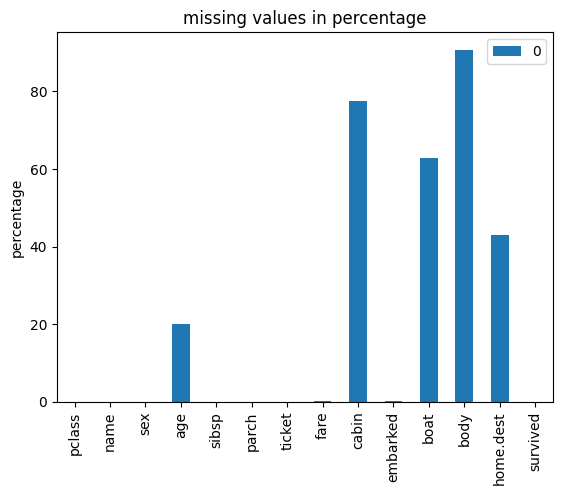

In [ ]:
missing_value=pd.DataFrame(df.isnull().sum()/len(df)*100)

missing_value.plot(kind='bar',title='missing values in percentage',ylabel='percentage')

In [ ]:
df['family']=df['sibsp']+df['parch']
df.loc[df['family'] > 0,'travelled_alone'] =0
df.loc[df['family']==0,'travelled_alone'] =1

In [ ]:
df['family'].head()

,family
0,0
1,3
2,3
3,3
4,3


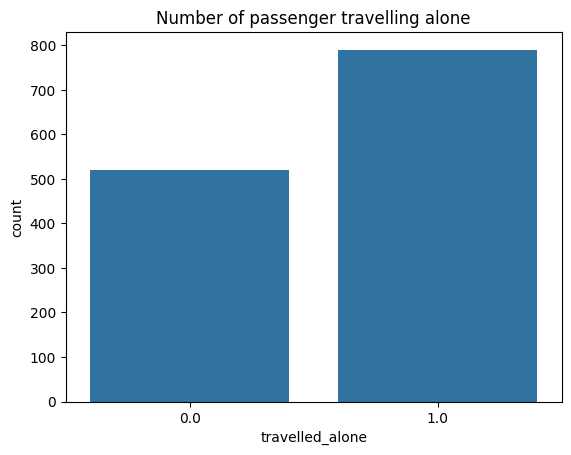

In [ ]:
df.drop(['sibsp','parch'],axis=1,inplace=True)
sns.countplot(x='travelled_alone',data=df)
plt.title('Number of passenger travelling alone')
plt.show()

In [ ]:
df.head()

,pclass,name,sex,age,ticket,fare,cabin,embarked,boat,body,home.dest,survived,family,travelled_alone
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1,0,1.0
1,1,"Allison, Master. Hudson Trevor",male,0.9167,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1,3,0.0
2,1,"Allison, Miss. Helen Loraine",female,2.0000,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0,3,0.0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0,3,0.0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0,3,0.0


In [ ]:
df.drop(['name','home.dest'],axis=1,inplace=True)

In [ ]:
df.drop(['ticket'],axis=1,inplace=True)

In [ ]:
df.head()

,pclass,sex,age,fare,cabin,embarked,boat,body,survived,family,travelled_alone
0,1,female,29.0000,211.3375,B5,S,2,NaN,1,0,1.0
1,1,male,0.9167,151.5500,C22 C26,S,11,NaN,1,3,0.0
2,1,female,2.0000,151.5500,C22 C26,S,NaN,NaN,0,3,0.0
3,1,male,30.0000,151.5500,C22 C26,S,NaN,135.0,0,3,0.0
4,1,female,25.0000,151.5500,C22 C26,S,NaN,NaN,0,3,0.0


In [ ]:
df.drop(['cabin','body','boat'],axis=1,inplace=True)

In [ ]:
df.head()

,pclass,sex,age,fare,embarked,survived,family,travelled_alone
0,1,female,29.0000,211.3375,S,1,0,1.0
1,1,male,0.9167,151.5500,S,1,3,0.0
2,1,female,2.0000,151.5500,S,0,3,0.0
3,1,male,30.0000,151.5500,S,0,3,0.0
4,1,female,25.0000,151.5500,S,0,3,0.0


In [ ]:
sex=pd.get_dummies(df['sex'],drop_first=True)
print(sex)
# here drop_first will drop the first column that is female

       male
0     False
1      True
2     False
3      True
4     False
...     ...
1304  False
1305  False
1306   True
1307   True
1308   True

[1309 rows x 1 columns]


In [ ]:
df['sex']=sex

In [ ]:
df.isnull().sum()

,0
pclass,0
sex,0
age,263
fare,1
embarked,2
survived,0
family,0
travelled_alone,0


In [ ]:
from sklearn.impute import SimpleImputer
imp_mean = SimpleImputer(strategy='mean')


In [ ]:
df['age']=imp_mean.fit_transform(df[['age']])
df['fare']=imp_mean.fit_transform(df[['fare']])

In [ ]:
df.isnull().sum()

,0
pclass,0
sex,0
age,0
fare,0
embarked,2
survived,0
family,0
travelled_alone,0


In [ ]:
imp_freq = SimpleImputer(strategy='most_frequent')
df['embarked'] = imp_freq.fit_transform(df[['embarked']]).ravel()

In [ ]:
df.isnull().sum()

,0
pclass,0
sex,0
age,0
fare,0
embarked,0
survived,0
family,0
travelled_alone,0


In [ ]:
df.head()

,pclass,sex,age,fare,embarked,survived,family,travelled_alone
0,1,False,29.0000,211.3375,S,1,0,1.0
1,1,True,0.9167,151.5500,S,1,3,0.0
2,1,False,2.0000,151.5500,S,0,3,0.0
3,1,True,30.0000,151.5500,S,0,3,0.0
4,1,False,25.0000,151.5500,S,0,3,0.0


In [ ]:
# Here the embarked column has characters value which need to changed to integer value. This is how it is done:
embark=pd.get_dummies(df['embarked'],drop_first=True)
print(embark)

          Q      S
0     False   True
1     False   True
2     False   True
3     False   True
4     False   True
...     ...    ...
1304  False  False
1305  False  False
1306  False  False
1307  False  False
1308  False   True

[1309 rows x 2 columns]


In [ ]:
df.drop(['embarked'],axis=1,inplace=True)

In [ ]:
df =pd.concat([df,embark],axis=1)

In [ ]:
df.head()

,pclass,sex,age,fare,survived,family,travelled_alone,Q,S
0,1,False,29.0000,211.3375,1,0,1.0,False,True
1,1,True,0.9167,151.5500,1,3,0.0,False,True
2,1,False,2.0000,151.5500,0,3,0.0,False,True
3,1,True,30.0000,151.5500,0,3,0.0,False,True
4,1,False,25.0000,151.5500,0,3,0.0,False,True


In [ ]:
x= df.drop(['survived'],axis=1)
x.head()

,pclass,sex,age,fare,family,travelled_alone,Q,S
0,1,False,29.0000,211.3375,0,1.0,False,True
1,1,True,0.9167,151.5500,3,0.0,False,True
2,1,False,2.0000,151.5500,3,0.0,False,True
3,1,True,30.0000,151.5500,3,0.0,False,True
4,1,False,25.0000,151.5500,3,0.0,False,True


In [ ]:
y=df['survived']
y.head()

,survived
0,1
1,1
2,0
3,0
4,0


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=1)

In [ ]:
print(X_train.shape,y_train.shape)

(916, 8) (916,)


In [ ]:
print(X_test.shape,y_test.shape)

(393, 8) (393,)


In [ ]:
from sklearn.linear_model import LogisticRegression
mod=LogisticRegression()
mod.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
pred = mod.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy_score(y_test,pred)

0.7964376590330788

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,pred)

array([[204,  32],
       [ 48, 109]])